In [7]:
# ============================================================
# CELL 1 — Imports
# Full-dataset SHAP for the actual weighted late-fusion model
# ============================================================

import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")
print("Random seed:", SEED)
print("SHAP version:", shap.__version__)

Libraries imported successfully.
Random seed: 42
SHAP version: 0.49.1


In [8]:
# ============================================================
# CELL 2 — Paths and feature definitions
# ============================================================

MASTER_PATH = r"C:\Users\hp\StressDetection\master_features_restored.csv"

OUTPUT_DIR = r"C:\Users\hp\StressDetection\ML\late_fusion_shap_FULL"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Stream 1 — 25 geometric features
# ------------------------------------------------------------

GEO_FEATURES = [
    "EAR_mean", "EAR_std", "EAR_min", "EAR_max", "EAR_range",
    "blink_mean", "blink_std", "blink_min", "blink_max", "blink_range",
    "gaze_mean", "gaze_std", "gaze_min", "gaze_max", "gaze_range",
    "brow_mean", "brow_std", "brow_min", "brow_max", "brow_range",
    "lip_mean", "lip_std", "lip_min", "lip_max", "lip_range"
]

# ------------------------------------------------------------
# Stream 2 — 4 emotional-valence features
# ------------------------------------------------------------

VAL_FEATURES = [
    "valence_mean",
    "valence_std",
    "valence_min",
    "valence_max"
]

ALL_FEATURES = GEO_FEATURES + VAL_FEATURES

PARTICIPANT_COL = "participant"
TARGET_COL = "label"

# ------------------------------------------------------------
# Load dataset
# ------------------------------------------------------------

if not os.path.exists(MASTER_PATH):
    raise FileNotFoundError(
        f"Dataset not found:\n{MASTER_PATH}"
    )

df = pd.read_csv(MASTER_PATH)

required_columns = (
    ALL_FEATURES +
    [PARTICIPANT_COL, TARGET_COL]
)

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns:\n" +
        "\n".join(missing_columns)
    )

X = df[ALL_FEATURES].copy()
y = df[TARGET_COL].astype(int).to_numpy()
groups = df[PARTICIPANT_COL].to_numpy()

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Rows:", len(df))
print("Participants:", df[PARTICIPANT_COL].nunique())
print("Geometric features:", len(GEO_FEATURES))
print("Valence features:", len(VAL_FEATURES))
print("Total features:", len(ALL_FEATURES))

print("\nLabel distribution:")
print(pd.Series(y).value_counts().sort_index())

DATASET INFORMATION
Rows: 29736
Participants: 56
Geometric features: 25
Valence features: 4
Total features: 29

Label distribution:
0     9912
1    19824
Name: count, dtype: int64


In [9]:
# ============================================================
# CELL 3 — Canonical XGBoost
# ============================================================

base_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
    verbosity=0
)

print(base_xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=-1, num_parallel_tree=None, random_state=42, ...)


In [10]:
# ============================================================
# CELL 4 — SHAP settings
# ============================================================

# IMPORTANT:
# ALL held-out samples will be explained.
# There is NO EXPLAIN_PER_FOLD limit.

# Background/reference samples are taken ONLY from training data.
BACKGROUND_SIZE = 100

# Minimum valid permutation budget for 29 features:
MAX_EVALS = 2 * len(ALL_FEATURES) + 1

print("FULL-DATASET SHAP")
print("Every held-out LOSO sample will be explained.")
print("Background size per fold:", BACKGROUND_SIZE)
print("MAX_EVALS:", MAX_EVALS)

FULL-DATASET SHAP
Every held-out LOSO sample will be explained.
Background size per fold: 100
MAX_EVALS: 59


In [11]:
# ============================================================
# CELL 5 — FULL LOSO + PERMUTATION SHAP
# Explain the ACTUAL weighted late-fusion predictor
# ============================================================

logo = LeaveOneGroupOut()

all_shap_values = []
all_base_values = []
all_explained_X = []
all_metadata = []
fold_weights = []

total_folds = logo.get_n_splits(X, y, groups)

print("=" * 80)
print("FULL-DATASET WEIGHTED LATE-FUSION SHAP")
print("=" * 80)
print("Total LOSO folds:", total_folds)
print("Total samples that will eventually be explained:", len(X))
print()

start_total = time.time()

for fold_number, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups),
    start=1
):

    fold_start = time.time()

    held_out_participant = groups[test_idx][0]

    # ========================================================
    # 1. TRAIN / TEST SPLIT
    # ========================================================

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y[train_idx]
    y_test = y[test_idx]

    X_geo_train = X_train[GEO_FEATURES]
    X_geo_test = X_test[GEO_FEATURES]

    X_val_train = X_train[VAL_FEATURES]
    X_val_test = X_test[VAL_FEATURES]

    # ========================================================
    # 2. FOLD-SAFE IMPUTATION
    # ========================================================

    geo_imputer = SimpleImputer(strategy="mean")
    val_imputer = SimpleImputer(strategy="mean")

    X_geo_train_imp = geo_imputer.fit_transform(X_geo_train)
    X_geo_test_imp = geo_imputer.transform(X_geo_test)

    X_val_train_imp = val_imputer.fit_transform(X_val_train)
    X_val_test_imp = val_imputer.transform(X_val_test)

    # ========================================================
    # 3. TRAIN TWO SEPARATE XGBOOST MODELS
    # ========================================================

    geo_model = clone(base_xgb_model)
    val_model = clone(base_xgb_model)

    geo_model.fit(X_geo_train_imp, y_train)
    val_model.fit(X_val_train_imp, y_train)

    # ========================================================
    # 4. SAME TRAINING-ACCURACY FUSION WEIGHTS
    # ========================================================

    geo_train_pred = geo_model.predict(
        X_geo_train_imp
    )

    val_train_pred = val_model.predict(
        X_val_train_imp
    )

    geo_train_acc = accuracy_score(
        y_train,
        geo_train_pred
    )

    val_train_acc = accuracy_score(
        y_train,
        val_train_pred
    )

    weight_sum = (
        geo_train_acc +
        val_train_acc
    )

    if weight_sum == 0:
        weight_geo = 0.5
        weight_val = 0.5
    else:
        weight_geo = (
            geo_train_acc /
            weight_sum
        )

        weight_val = (
            val_train_acc /
            weight_sum
        )

    fold_weights.append({
        "fold": fold_number,
        "participant": held_out_participant,
        "geo_train_accuracy": geo_train_acc,
        "valence_train_accuracy": val_train_acc,
        "weight_geo": weight_geo,
        "weight_valence": weight_val,
        "test_samples": len(X_test)
    })

    # ========================================================
    # 5. ACTUAL WEIGHTED LATE-FUSION FUNCTION
    # ========================================================

    def late_fusion_predict(data):

        if isinstance(data, pd.DataFrame):
            data_array = data.to_numpy(
                dtype=float
            )
        else:
            data_array = np.asarray(
                data,
                dtype=float
            )

        # First 25 features = geometric stream
        geo_raw = data_array[
            :, :len(GEO_FEATURES)
        ]

        # Last 4 features = valence stream
        val_raw = data_array[
            :, len(GEO_FEATURES):
        ]

        # Same fold-specific imputers
        geo_imp = geo_imputer.transform(
            geo_raw
        )

        val_imp = val_imputer.transform(
            val_raw
        )

        # Two stream probabilities
        p_geo = geo_model.predict_proba(
            geo_imp
        )[:, 1]

        p_val = val_model.predict_proba(
            val_imp
        )[:, 1]

        # Actual weighted late fusion
        p_final = (
            weight_geo * p_geo +
            weight_val * p_val
        )

        return p_final

    # ========================================================
    # 6. VERIFY FUSION PREDICTIONS
    # ========================================================

    geo_prob = geo_model.predict_proba(
        X_geo_test_imp
    )[:, 1]

    val_prob = val_model.predict_proba(
        X_val_test_imp
    )[:, 1]

    fusion_prob_direct = (
        weight_geo * geo_prob +
        weight_val * val_prob
    )

    fusion_prob_function = (
        late_fusion_predict(X_test)
    )

    if not np.allclose(
        fusion_prob_direct,
        fusion_prob_function,
        atol=1e-10
    ):
        raise RuntimeError(
            f"Fusion prediction mismatch "
            f"in fold {fold_number}"
        )

    fusion_pred = (
        fusion_prob_direct >= 0.5
    ).astype(int)

    # ========================================================
    # 7. TRAINING-ONLY SHAP BACKGROUND
    # ========================================================

    rng = np.random.default_rng(
        SEED + fold_number
    )

    background_n = min(
        BACKGROUND_SIZE,
        len(X_train)
    )

    background_indices = rng.choice(
        len(X_train),
        size=background_n,
        replace=False
    )

    background = (
        X_train
        .iloc[background_indices]
        .copy()
    )

    # ========================================================
    # 8. EXPLAIN ALL HELD-OUT WINDOWS
    # ========================================================

    # NO SAMPLING HERE.
    X_explain = X_test.copy()

    masker = shap.maskers.Independent(
        background
    )

    explainer = shap.Explainer(
        late_fusion_predict,
        masker,
        algorithm="permutation",
        feature_names=ALL_FEATURES
    )

    shap_values = explainer(
        X_explain,
        max_evals=MAX_EVALS,
        silent=True
    )

    # ========================================================
    # 9. SAVE FOLD EXPLANATIONS
    # ========================================================

    all_shap_values.append(
        shap_values.values
    )

    all_base_values.append(
        np.asarray(shap_values.base_values)
    )

    all_explained_X.append(
        X_explain.to_numpy()
    )

    for local_i, original_row in enumerate(
        test_idx
    ):

        all_metadata.append({
            "fold": fold_number,
            "participant": held_out_participant,
            "original_row": int(original_row),
            "true_label": int(y_test[local_i]),
            "fusion_probability": float(
                fusion_prob_direct[local_i]
            ),
            "fusion_prediction": int(
                fusion_pred[local_i]
            ),
            "weight_geo": weight_geo,
            "weight_valence": weight_val
        })

    # ========================================================
    # 10. PROGRESS
    # ========================================================

    fold_time = (
        time.time() -
        fold_start
    )

    elapsed = (
        time.time() -
        start_total
    )

    average_fold_time = (
        elapsed /
        fold_number
    )

    estimated_remaining = (
        average_fold_time *
        (total_folds - fold_number)
    )

    print(
        f"Fold {fold_number:02d}/{total_folds} | "
        f"Participant {held_out_participant} | "
        f"Explained {len(X_test)} ALL samples | "
        f"wg={weight_geo:.3f}, "
        f"wv={weight_val:.3f} | "
        f"{fold_time:.1f} sec | "
        f"ETA {estimated_remaining / 60:.1f} min"
    )


total_time = (
    time.time() -
    start_total
)

print()
print("=" * 80)
print("FULL LOSO SHAP COMPLETED")
print("=" * 80)
print(
    f"Total time: "
    f"{total_time / 60:.2f} minutes"
)

FULL-DATASET WEIGHTED LATE-FUSION SHAP
Total LOSO folds: 56
Total samples that will eventually be explained: 29736

Fold 01/56 | Participant 1 | Explained 531 ALL samples | wg=0.558, wv=0.442 | 30.4 sec | ETA 27.9 min
Fold 02/56 | Participant 2 | Explained 531 ALL samples | wg=0.558, wv=0.442 | 24.3 sec | ETA 24.6 min
Fold 03/56 | Participant 3 | Explained 531 ALL samples | wg=0.557, wv=0.443 | 23.8 sec | ETA 23.1 min
Fold 04/56 | Participant 4 | Explained 531 ALL samples | wg=0.558, wv=0.442 | 23.9 sec | ETA 22.2 min
Fold 05/56 | Participant 5 | Explained 531 ALL samples | wg=0.557, wv=0.443 | 23.8 sec | ETA 21.5 min
Fold 06/56 | Participant 6 | Explained 531 ALL samples | wg=0.557, wv=0.443 | 23.9 sec | ETA 20.9 min
Fold 07/56 | Participant 7 | Explained 531 ALL samples | wg=0.557, wv=0.443 | 23.8 sec | ETA 20.3 min
Fold 08/56 | Participant 8 | Explained 531 ALL samples | wg=0.558, wv=0.442 | 23.9 sec | ETA 19.8 min
Fold 09/56 | Participant 9 | Explained 531 ALL samples | wg=0.558, w

In [12]:
# ============================================================
# CELL 6 — Combine all LOSO explanations
# ============================================================

shap_matrix = np.vstack(
    all_shap_values
)

X_explained_matrix = np.vstack(
    all_explained_X
)

base_values = np.concatenate([
    np.atleast_1d(v)
    for v in all_base_values
])

metadata_df = pd.DataFrame(
    all_metadata
)

weights_df = pd.DataFrame(
    fold_weights
)

print("=" * 70)
print("FULL-DATASET SHAP MATRICES")
print("=" * 70)

print(
    "SHAP matrix:",
    shap_matrix.shape
)

print(
    "Feature matrix:",
    X_explained_matrix.shape
)

print(
    "Metadata:",
    metadata_df.shape
)

print(
    "Base values:",
    base_values.shape
)

# Every dataset sample must have been explained exactly once.
assert shap_matrix.shape[0] == len(df)

assert (
    X_explained_matrix.shape[0]
    == len(df)
)

assert (
    metadata_df.shape[0]
    == len(df)
)

assert (
    shap_matrix.shape[1]
    == len(ALL_FEATURES)
)

assert (
    metadata_df["original_row"].nunique()
    == len(df)
)

print()
print(
    "SUCCESS: Every dataset window "
    "was explained exactly once as "
    "a held-out LOSO sample."
)

FULL-DATASET SHAP MATRICES
SHAP matrix: (29736, 29)
Feature matrix: (29736, 29)
Metadata: (29736, 8)
Base values: (29736,)

SUCCESS: Every dataset window was explained exactly once as a held-out LOSO sample.


In [13]:
# ============================================================
# CELL 7 — SHAP additivity verification
# ============================================================

shap_reconstructed_probability = (
    base_values +
    shap_matrix.sum(axis=1)
)

actual_probability = (
    metadata_df[
        "fusion_probability"
    ].to_numpy()
)

absolute_error = np.abs(
    shap_reconstructed_probability -
    actual_probability
)

print("=" * 70)
print("SHAP ADDITIVITY CHECK")
print("=" * 70)

print(
    "Mean absolute reconstruction error:",
    absolute_error.mean()
)

print(
    "Maximum absolute reconstruction error:",
    absolute_error.max()
)

print(
    "Mean actual fusion probability:",
    actual_probability.mean()
)

print(
    "Mean SHAP-reconstructed probability:",
    shap_reconstructed_probability.mean()
)

SHAP ADDITIVITY CHECK
Mean absolute reconstruction error: 0.0012971242251535434
Maximum absolute reconstruction error: 0.3856391916051507
Mean actual fusion probability: 0.6687331113425057
Mean SHAP-reconstructed probability: 0.6690693326938185


In [14]:
# ============================================================
# CELL 8 — Confirm LOSO fusion performance
# ============================================================

y_true_full = (
    metadata_df["true_label"]
    .astype(int)
    .to_numpy()
)

y_pred_full = (
    metadata_df["fusion_prediction"]
    .astype(int)
    .to_numpy()
)

full_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],
    "Value": [
        accuracy_score(
            y_true_full,
            y_pred_full
        ),
        balanced_accuracy_score(
            y_true_full,
            y_pred_full
        ),
        precision_score(
            y_true_full,
            y_pred_full,
            zero_division=0
        ),
        recall_score(
            y_true_full,
            y_pred_full,
            zero_division=0
        ),
        f1_score(
            y_true_full,
            y_pred_full,
            zero_division=0
        )
    ]
})

full_metrics["Percentage"] = (
    full_metrics["Value"] *
    100
)

display(full_metrics)

,Metric,Value,Percentage
0,Accuracy,0.940005,94.000538
1,Balanced Accuracy,0.930488,93.048830
2,Precision,0.951361,95.136109
3,Recall,0.959040,95.903955
4,F1,0.955185,95.518489


In [15]:
# ============================================================
# CELL 9 — Global feature importance
# ============================================================

mean_abs_shap = np.mean(
    np.abs(shap_matrix),
    axis=0
)

importance_df = pd.DataFrame({
    "Feature": ALL_FEATURES,
    "MeanAbsSHAP": mean_abs_shap
})

importance_df = (
    importance_df
    .sort_values(
        "MeanAbsSHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

importance_df["Percentage"] = (
    importance_df["MeanAbsSHAP"]
    /
    importance_df["MeanAbsSHAP"].sum()
    *
    100
)

print("=" * 70)
print("FULL-DATASET LATE-FUSION SHAP")
print("INDIVIDUAL FEATURE RANKING")
print("=" * 70)

display(importance_df)

FULL-DATASET LATE-FUSION SHAP
INDIVIDUAL FEATURE RANKING


,Feature,MeanAbsSHAP,Percentage
0,valence_max,0.093291,20.036383
1,lip_max,0.062192,13.357060
2,lip_mean,0.048069,10.323914
3,lip_range,0.037610,8.077584
4,valence_std,0.027708,5.950978
5,lip_std,0.025931,5.569213
6,valence_min,0.024074,5.170480
7,valence_mean,0.019145,4.111829
8,blink_std,0.016400,3.522210
9,EAR_mean,0.014282,3.067486


In [16]:
# ============================================================
# CELL 10 — Group-level SHAP importance
# ============================================================

def feature_group(feature):

    if feature.startswith("EAR_"):
        return "EAR"

    if feature.startswith("blink_"):
        return "Blink"

    if feature.startswith("gaze_"):
        return "Gaze"

    if feature.startswith("brow_"):
        return "Eyebrows"

    if feature.startswith("lip_"):
        return "Lips"

    if feature.startswith("valence_"):
        return "Valence"

    return "Other"


importance_df["Group"] = (
    importance_df["Feature"]
    .apply(feature_group)
)

group_importance = (
    importance_df
    .groupby(
        "Group",
        as_index=False
    )["MeanAbsSHAP"]
    .sum()
)

group_importance["Percentage"] = (
    group_importance["MeanAbsSHAP"]
    /
    group_importance[
        "MeanAbsSHAP"
    ].sum()
    *
    100
)

group_importance = (
    group_importance
    .sort_values(
        "MeanAbsSHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("FULL-DATASET GROUPED SHAP IMPORTANCE")
print("=" * 70)

display(group_importance)

FULL-DATASET GROUPED SHAP IMPORTANCE


,Group,MeanAbsSHAP,Percentage
0,Lips,0.179910,38.639684
1,Valence,0.164219,35.269669
2,Gaze,0.034312,7.369263
3,Blink,0.031928,6.857161
4,Eyebrows,0.028352,6.089271
5,EAR,0.026889,5.774952


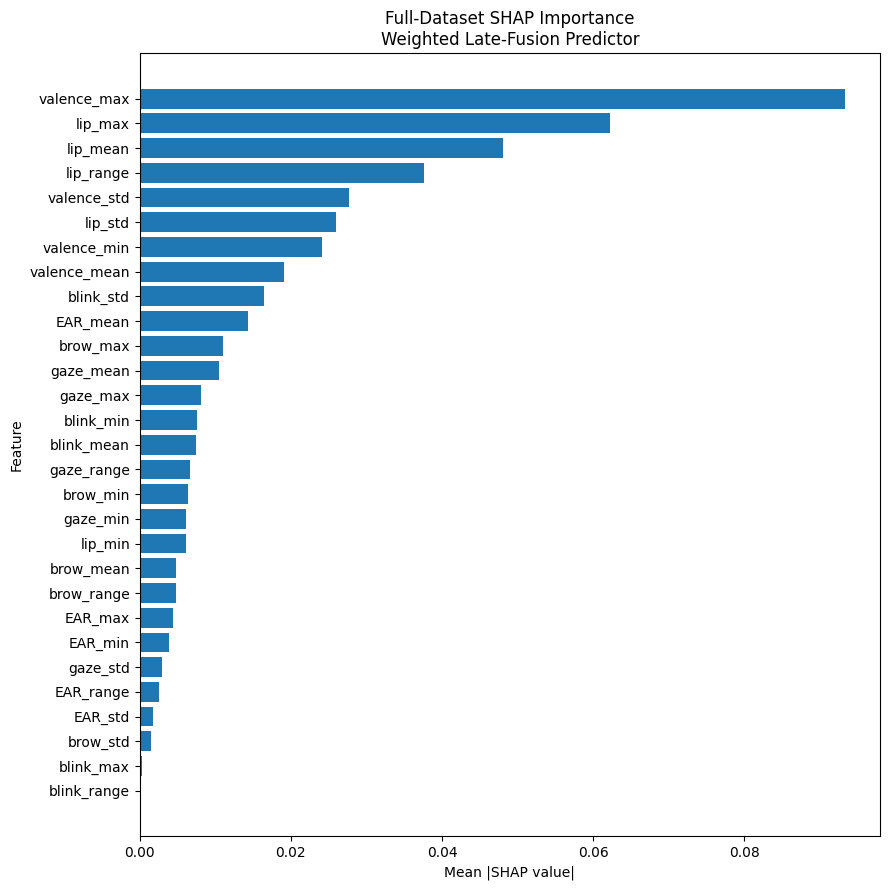

Saved: C:\Users\hp\StressDetection\ML\late_fusion_shap_FULL\full_late_fusion_shap_features.png


In [17]:
# ============================================================
# CELL 11 — Individual-feature SHAP plot
# ============================================================

plot_df = (
    importance_df
    .sort_values(
        "MeanAbsSHAP",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 9)
)

plt.barh(
    plot_df["Feature"],
    plot_df["MeanAbsSHAP"]
)

plt.xlabel(
    "Mean |SHAP value|"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Full-Dataset SHAP Importance\n"
    "Weighted Late-Fusion Predictor"
)

plt.tight_layout()

feature_plot_path = os.path.join(
    OUTPUT_DIR,
    "full_late_fusion_shap_features.png"
)

plt.savefig(
    feature_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    feature_plot_path
)

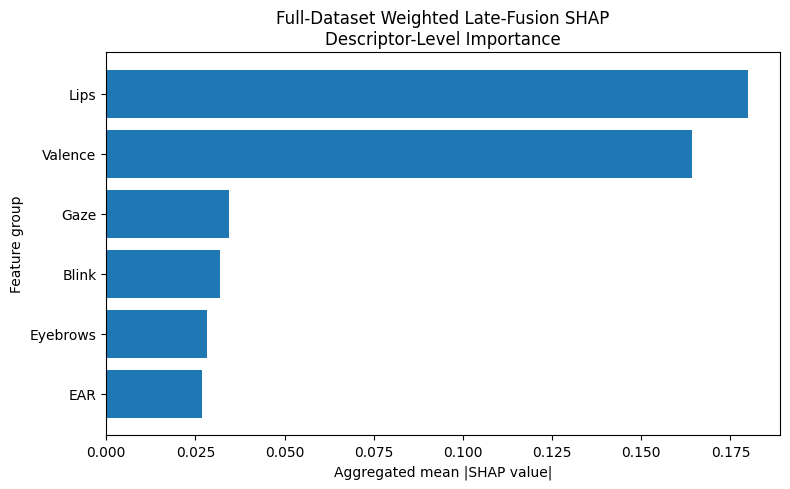

Saved: C:\Users\hp\StressDetection\ML\late_fusion_shap_FULL\full_late_fusion_shap_groups.png


In [18]:
# ============================================================
# CELL 12 — Descriptor-group SHAP plot
# ============================================================

plot_groups = (
    group_importance
    .sort_values(
        "MeanAbsSHAP",
        ascending=True
    )
)

plt.figure(
    figsize=(8, 5)
)

plt.barh(
    plot_groups["Group"],
    plot_groups["MeanAbsSHAP"]
)

plt.xlabel(
    "Aggregated mean |SHAP value|"
)

plt.ylabel(
    "Feature group"
)

plt.title(
    "Full-Dataset Weighted Late-Fusion SHAP\n"
    "Descriptor-Level Importance"
)

plt.tight_layout()

group_plot_path = os.path.join(
    OUTPUT_DIR,
    "full_late_fusion_shap_groups.png"
)

plt.savefig(
    group_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    group_plot_path
)

In [19]:
# ============================================================
# DIAGNOSE SHAP APPROXIMATION ERROR
# ============================================================

error_df = pd.DataFrame({
    "absolute_error": absolute_error
})

print("Total samples:", len(error_df))

for threshold in [0.001, 0.005, 0.01, 0.05, 0.10, 0.20]:
    n = (error_df["absolute_error"] > threshold).sum()
    pct = n / len(error_df) * 100

    print(
        f"Error > {threshold:.3f}: "
        f"{n} samples ({pct:.4f}%)"
    )

print("\nError quantiles:")
print(
    error_df["absolute_error"].quantile(
        [0.50, 0.90, 0.95, 0.99, 0.999, 1.0]
    )
)

Total samples: 29736
Error > 0.001: 1329 samples (4.4693%)
Error > 0.005: 1009 samples (3.3932%)
Error > 0.010: 756 samples (2.5424%)
Error > 0.050: 244 samples (0.8206%)
Error > 0.100: 66 samples (0.2220%)
Error > 0.200: 5 samples (0.0168%)

Error quantiles:
0.500    0.000000e+00
0.900    5.551115e-17
0.950    1.110223e-16
0.990    4.600821e-02
0.999    1.234416e-01
1.000    3.856392e-01
Name: absolute_error, dtype: float64


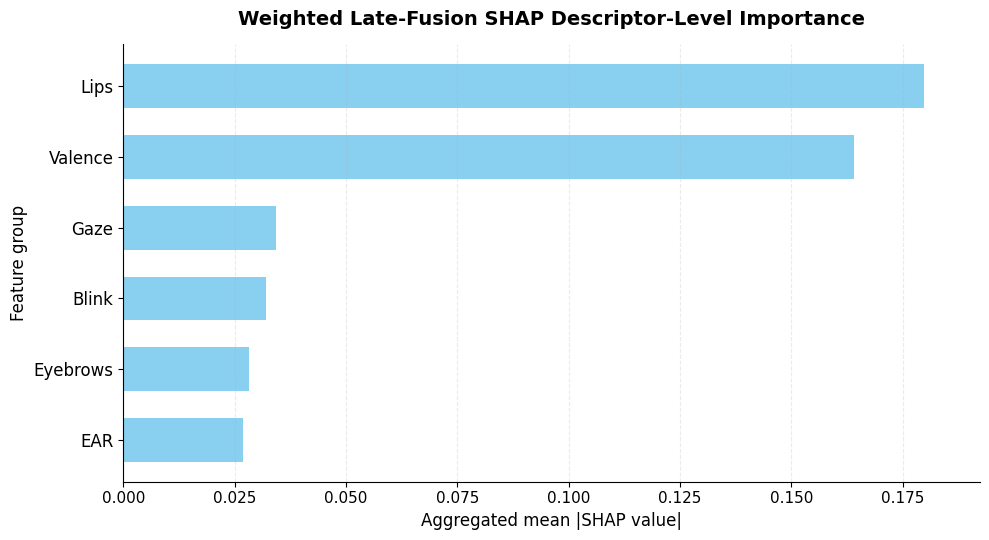

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Full-dataset model-agnostic SHAP results
# Weighted late-fusion predictor
# ============================================================

groups = [
    "Lips",
    "Valence",
    "Gaze",
    "Blink",
    "Eyebrows",
    "EAR"
]

# Aggregated mean absolute SHAP values
# Corresponding to the full-dataset SHAP analysis
values = [
    0.1798,   # Lips
    0.1641,   # Valence
    0.0343,   # Gaze
    0.0320,   # Blink
    0.0283,   # Eyebrows
    0.0269    # EAR
]

# ============================================================
# Create figure
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5.5))

y = np.arange(len(groups))

# Thinner horizontal bars
ax.barh(
    y,
    values,
    height=0.62,
    color="#89CFF0",
    edgecolor="none"
)
# Put highest importance at the top
ax.invert_yaxis()

# ============================================================
# Labels
# ============================================================

ax.set_yticks(y)
ax.set_yticklabels(groups, fontsize=12)

ax.set_xlabel(
    "Aggregated mean |SHAP value|",
    fontsize=12
)

ax.set_ylabel(
    "Feature group",
    fontsize=12
)

ax.set_title(
    "Weighted Late-Fusion SHAP Descriptor-Level Importance",
    fontsize=14,
    fontweight="bold",
    pad=14
)

# ============================================================
# Clean academic style
# ============================================================

# Light vertical grid only
ax.xaxis.grid(
    True,
    linestyle="--",
    alpha=0.25,
    linewidth=0.8
)

ax.yaxis.grid(False)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

ax.tick_params(axis="x", labelsize=11)
ax.tick_params(axis="y", labelsize=12)

# Give a little space after longest bar
ax.set_xlim(0, max(values) * 1.07)

plt.tight_layout()

# ============================================================
# Save high-resolution figure for the paper
# ============================================================

plt.savefig(
    "full_late_fusion_shap_groups_publication.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()